# Neuroblastoma single-cell UMAP with cluster examples

Computes a UMAP of the single cells of the neuroblastoma cell lines, groups the cells into clusters, and finds representative cells of each cluster to show as images.

**Why:** neuroblastoma is the cancer group with the most cell lines (12).
Showing what the clusters of its UMAP look like, and which cell lines they come from, shows how the cell lines differ at the level of single cells.

**Input:** `<plate>_sc_feature_selected.parquet` of the plates that have neuroblastoma cell lines (multivariate).
Each plate has its own features, so the UMAP uses the features that these plates share.
The profiles of each plate are standardized to that plate.

**Method:** it is the method of `3.single_cell_embedding.ipynb` for one cancer group, with more cells.
At most `cells_per_line_per_plate` cells of each cell line on each plate are drawn at random (fixed seed), all time points are used, and the cells are clustered with k-means on the UMAP coordinates.
The representative cells of a cluster are the `examples_per_cluster` cells closest to its center.
Their images are cut from the raw images with `pccma_utils.cell_images` (`utils/pccma_utils/`; raw images, no illumination correction, each channel stretched in its own crop).

**Output:** in `results/5.neuroblastoma_single_cell/`
- `neuroblastoma_single_cell_umap_coordinates.parquet`: one row per sampled cell with the cell line, plate, well, site (field number), nucleus position in the image, time point, UMAP coordinates, and cluster.
- `neuroblastoma_cluster_cell_line_composition.csv`: the number and the share of the cells of each cluster that come from each cell line.
- `neuroblastoma_cluster_example_cells.csv` and `neuroblastoma_cluster_example_cells/`: the representative cells (`selection` says how they were chosen) and their images (`cluster<n>_example<m>.png`).
- `neuroblastoma_umap_by_cluster_and_cell_line.png`: the UMAP colored by cluster and by cell line.

The notebook also shows the cell line composition of each cluster and the example cells; this view is displayed in the notebook and is not saved to disk.

## Import libraries

In [1]:
import pathlib
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import umap
from pccma_utils.cell_images import crop_cell, find_image_dir
from pccma_utils.cell_lines import load_cell_line_groups
from pccma_utils.profiles import numeric_features
from sklearn.cluster import KMeans

# UMAP warns that a fixed random seed runs it on one thread, which is what keeps the embedding reproducible
warnings.filterwarnings("ignore", message="n_jobs value")

## Set paths and parameters

In [2]:
metadata_path = pathlib.Path("../cell_lines/pccma_cell_line_metadata.csv")
groups_path = pathlib.Path("../cell_lines/plotting_helpers/cancer_type_categories.yaml")

# single-cell feature-selected profiles and raw images: use the local data folder and fall back to the bandicoot mount
local_dir = pathlib.Path("../4.preprocess_features/data/single_cell_profiles")
bandicoot_root = pathlib.Path("~/mnt/bandicoot/PCCMA_data").expanduser()
profile_dir = local_dir if any(local_dir.glob("BR*_sc_feature_selected.parquet")) else bandicoot_root / "Atlas_v2_profiles/single_cell_profiles"
screen_dir = bandicoot_root / "Atlas_v2_screen"

results_dir = pathlib.Path("./results/5.neuroblastoma_single_cell")
(results_dir / "neuroblastoma_cluster_example_cells").mkdir(parents=True, exist_ok=True)

cancer_group = "Neuroblastoma"
cells_per_line_per_plate = 2000  # cells drawn per cell line on each plate
n_clusters = 8
examples_per_cluster = 4  # representative cells shown per cluster
crop_size = 160  # pixels of an example image (about 95 um)
umap_parameters = {"n_neighbors": 15, "min_dist": 0.1, "n_components": 2, "metric": "euclidean", "random_state": 0}
rng_seed = 0

## Neuroblastoma cell lines, their plates, and the shared features

In [4]:
neuroblastoma_lines = load_cell_line_groups(metadata_path, groups_path).query("cancer_group == @cancer_group")["cell_line"]

plate_files = sorted(profile_dir.glob("BR*_sc_feature_selected.parquet"))
plate_files = [
    file for file in plate_files
    if pd.read_parquet(file, columns=["Metadata_cell_line"])["Metadata_cell_line"].isin(neuroblastoma_lines).any()
]

features = sorted(set.intersection(*[numeric_features(pq.read_schema(file)) for file in plate_files]))
print(f"{len(neuroblastoma_lines)} cell lines on {len(plate_files)} plates, {len(features)} features shared by these plates")

12 cell lines on 9 plates, 547 features shared by these plates


## Subsample the neuroblastoma cells

In [5]:
cell_columns = [
    "Metadata_Plate", "Metadata_Well", "Metadata_Site", "Metadata_cell_line", "Metadata_time_point",
    "Metadata_Nuclei_Location_Center_X", "Metadata_Nuclei_Location_Center_Y",
]

rng = np.random.default_rng(rng_seed)
sampled = []
for plate_file in plate_files:
    plate_df = pd.read_parquet(plate_file, columns=cell_columns + features)
    plate_df = plate_df[plate_df["Metadata_cell_line"].isin(neuroblastoma_lines)]
    chosen = [
        rng.choice(np.asarray(rows), size=min(len(rows), cells_per_line_per_plate), replace=False)
        for rows in plate_df.groupby("Metadata_cell_line").indices.values()
    ]
    sampled.append(plate_df.iloc[np.concatenate(chosen)])
    print(f"{plate_file.name}: {len(sampled[-1])} of {len(plate_df)} neuroblastoma cells")

cells_df = pd.concat(sampled, ignore_index=True)
print(f"{len(cells_df)} cells from {cells_df['Metadata_cell_line'].nunique()} cell lines")

BR00150695_sc_feature_selected.parquet: 6000 of 15808 neuroblastoma cells


BR00150696_sc_feature_selected.parquet: 6000 of 13641 neuroblastoma cells


BR00150697_sc_feature_selected.parquet: 6000 of 18355 neuroblastoma cells


BR00150698_sc_feature_selected.parquet: 12000 of 75736 neuroblastoma cells


BR00150699_sc_feature_selected.parquet: 12000 of 73085 neuroblastoma cells


BR00150700_sc_feature_selected.parquet: 12000 of 80848 neuroblastoma cells


BR00150701_sc_feature_selected.parquet: 6000 of 26414 neuroblastoma cells


BR00150702_sc_feature_selected.parquet: 6000 of 39909 neuroblastoma cells


BR00150703_sc_feature_selected.parquet: 5366 of 39347 neuroblastoma cells


71366 cells from 12 cell lines


## UMAP and clusters

In [6]:
embedding = umap.UMAP(**umap_parameters).fit_transform(cells_df[features].to_numpy())
cells_df["umap_1"], cells_df["umap_2"] = embedding[:, 0], embedding[:, 1]

kmeans = KMeans(n_clusters=n_clusters, n_init=10, random_state=rng_seed).fit(embedding)
cells_df["cluster"] = kmeans.labels_ + 1

keep = ["Metadata_cell_line", "Metadata_Plate", "Metadata_Well", "Metadata_Site", "Metadata_time_point",
        "Metadata_Nuclei_Location_Center_X", "Metadata_Nuclei_Location_Center_Y", "umap_1", "umap_2", "cluster"]
cells_df[keep].to_parquet(results_dir / "neuroblastoma_single_cell_umap_coordinates.parquet", compression="zstd")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for cluster, cluster_df in cells_df.groupby("cluster"):
    axes[0].scatter(cluster_df["umap_1"], cluster_df["umap_2"], s=1.5, alpha=0.6, label=cluster)
    axes[0].annotate(cluster, kmeans.cluster_centers_[cluster - 1], fontsize=12, weight="bold", ha="center")
for color, (line, line_df) in zip(plt.get_cmap("tab20").colors, cells_df.groupby("Metadata_cell_line")):
    axes[1].scatter(line_df["umap_1"], line_df["umap_2"], s=1.5, alpha=0.6, color=color, label=line)
axes[0].set(title="Clusters", xlabel="UMAP 1", ylabel="UMAP 2")
axes[1].set(title="Cell lines", xlabel="UMAP 1")
axes[1].legend(markerscale=6, fontsize=7, frameon=False, loc="center left", bbox_to_anchor=(1, 0.5))
fig.savefig(results_dir / "neuroblastoma_umap_by_cluster_and_cell_line.png", dpi=150, bbox_inches="tight")
plt.close(fig)

## Which cell lines make up each cluster

The number of cells of each cluster from each cell line, and the share of the cluster.

In [7]:
counts = cells_df.groupby(["cluster", "Metadata_cell_line"]).size().rename("n_cells").reset_index()
counts["share_of_cluster"] = counts["n_cells"] / counts.groupby("cluster")["n_cells"].transform("sum")
counts = counts.rename(columns={"Metadata_cell_line": "cell_line"})
counts.to_csv(results_dir / "neuroblastoma_cluster_cell_line_composition.csv", index=False)

print("Cell line with the largest share of each cluster:")
largest = counts.loc[counts.groupby("cluster")["share_of_cluster"].idxmax()]
print(largest.assign(cells_in_cluster=largest["cluster"].map(cells_df["cluster"].value_counts())).round(2).to_string(index=False))

Cell line with the largest share of each cluster:
 cluster cell_line  n_cells  share_of_cluster  cells_in_cluster
       1     SKNDZ     3131              0.36              8731
       2     IMR32     5251              0.49             10748
       3    CHP212     3067              0.30             10066
       4   KP-N-YN     2186              0.36              6000
       5      NB-1     4059              0.49              8344
       6  SKNAS-EV     4218              0.30             13868
       7    CHP134     3206              0.48              6737
       8   SK-N-AS     4873              0.71              6872


## Representative cell images

The cells closest to the center of each cluster, cut from the raw images of their plate.

In [8]:
example_index = []  # rows of the examples, the cells closest to the center of each cluster
example_number = []  # 1 for the cell closest to the center of its cluster, 2 for the next, and so on
for cluster in range(1, n_clusters + 1):
    in_cluster = np.where(cells_df["cluster"].to_numpy() == cluster)[0]
    distance = ((embedding[in_cluster] - kmeans.cluster_centers_[cluster - 1]) ** 2).sum(axis=1)
    closest = in_cluster[np.argsort(distance)[:examples_per_cluster]]
    example_index.extend(closest)
    example_number.extend(range(1, len(closest) + 1))

examples_df = cells_df.iloc[example_index][keep].reset_index(drop=True)
examples_df["example"] = example_number
examples_df["selection"] = "one of the cells closest to the center of its cluster (example 1 is the closest)"
examples_df["image_file"] = (
    "neuroblastoma_cluster_example_cells/cluster" + examples_df["cluster"].astype(str) + "_example" + examples_df["example"].astype(str) + ".png"
)

for cell in examples_df.itertuples():
    image = crop_cell(
        find_image_dir(screen_dir, cell.Metadata_Plate), cell.Metadata_Well, cell.Metadata_Site,
        cell.Metadata_Nuclei_Location_Center_X, cell.Metadata_Nuclei_Location_Center_Y, size=crop_size,
    )
    plt.imsave(results_dir / cell.image_file, np.clip(image, 0, 1))

examples_df.to_csv(results_dir / "neuroblastoma_cluster_example_cells.csv", index=False)
print(f"{len(examples_df)} example cell images saved")

32 example cell images saved


## The clusters at a glance

The share of the cells of each cluster that comes from each cell line, and the representative cells of each cluster (one row per cluster, the cells closest to its center).
The views are displayed here and not saved to disk.

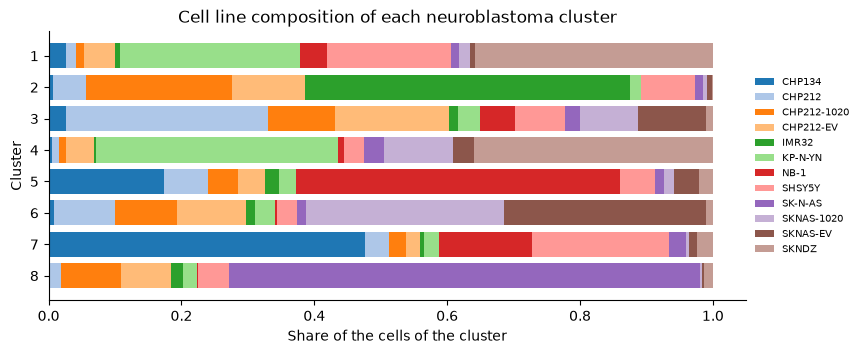

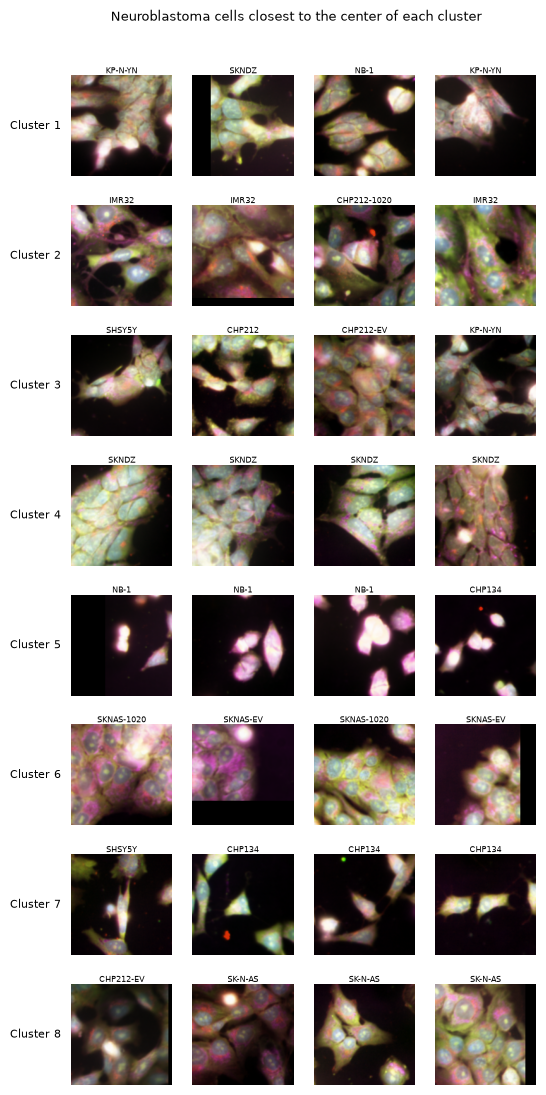

In [4]:
share = counts.pivot(index="cluster", columns="cell_line", values="share_of_cluster").fillna(0)
fig, ax = plt.subplots(figsize=(9, 3.5))
left = np.zeros(len(share))
for color, line in zip(plt.get_cmap("tab20").colors, share.columns):
    ax.barh(share.index, share[line], left=left, color=color, label=line)
    left += share[line].to_numpy()
ax.set_yticks(share.index)
ax.invert_yaxis()
ax.set(title="Cell line composition of each neuroblastoma cluster", xlabel="Share of the cells of the cluster", ylabel="Cluster")
ax.legend(fontsize=7, frameon=False, loc="center left", bbox_to_anchor=(1, 0.5))
ax.spines[["top", "right"]].set_visible(False)
plt.show()

fig, axes = plt.subplots(n_clusters, examples_per_cluster, figsize=(1.5 * examples_per_cluster, 1.5 * n_clusters + 0.4))
for ax, example in zip(axes.ravel(), examples_df.itertuples()):
    ax.imshow(plt.imread(results_dir / example.image_file))
    ax.set_title(example.Metadata_cell_line, fontsize=6, pad=1)
for ax in axes.ravel():
    ax.axis("off")
for cluster, ax in enumerate(axes[:, 0], start=1):
    ax.text(-0.1, 0.5, f"Cluster {cluster}", transform=ax.transAxes, ha="right", va="center", fontsize=8)
fig.suptitle("Neuroblastoma cells closest to the center of each cluster", fontsize=9)
fig.subplots_adjust(top=0.93)
plt.show()